# History-dependent and rough processes

This notebook uses generated paths to inspect family 14. Standard fractional Brownian motion and fractional Volterra processes share a variance scaling but have different temporal covariance. Rough Bergomi combines a Volterra variance history with a correlated asset driver. We keep kernel approximation, time discretization, and Monte Carlo uncertainty separate.

See [the catalog and contracts](../docs/rough_processes.md) for equations, shapes, and limitations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from convexity.math import rough as r

rng = np.random.default_rng(140)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': .2})
times = np.linspace(0, 1, 65)

## Fractional histories

Both models have variance $t^{2H}$. Only standard fBm has stationary increments. These are separate draws; visual path differences are not a coupled approximation error.

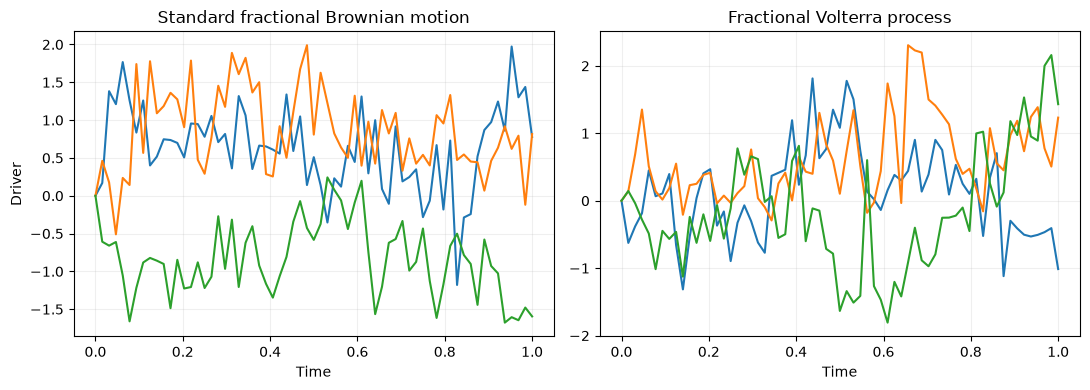

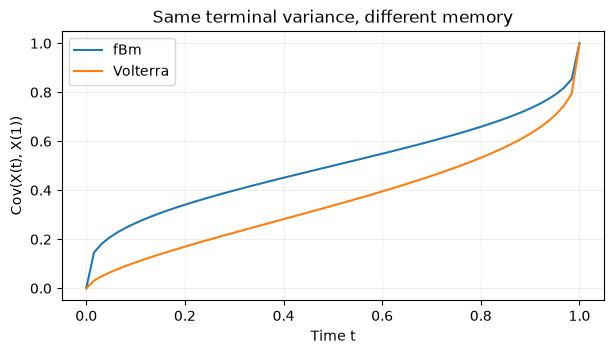

In [2]:
h = .15
fbm = r.FractionalBrownianMotion(h)
volterra = r.VolterraGaussian(r.FractionalKernel(h))
a = fbm.sample(times, draws=3, rng=rng)
b = volterra.sample(times, draws=3, rng=rng)
fig, axes = plt.subplots(1, 2)
axes[0].plot(times, a.values.T)
axes[0].set(title='Standard fractional Brownian motion', xlabel='Time', ylabel='Driver')
axes[1].plot(times, b.values.T)
axes[1].set(title='Fractional Volterra process', xlabel='Time')
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(times, fbm.covariance(times)[:, -1], label='fBm')
ax.plot(times, volterra.covariance(times)[:, -1], label='Volterra')
ax.set(xlabel='Time t', ylabel='Cov(X(t), X(1))', title='Same terminal variance, different memory')
ax.legend()
plt.show()

## Rough Bergomi paths and the initial forward curve

The variance driver is sampled jointly with its Brownian increments. Spot uses left endpoint variance in log Euler. The driver grid law is exact up to numerical integration; spot integration remains approximate.

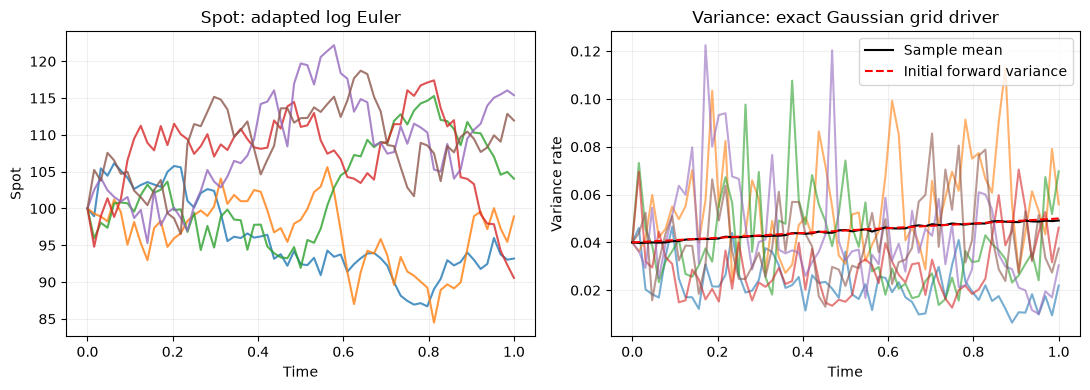

,quantity,sample mean,MC standard error,reference mean
0,Terminal spot,100.402811,0.319572,100.00
1,Terminal variance,0.049169,0.000598,0.05


In [3]:
curve = r.ForwardVarianceCurve([0, .5, 1, 2], [.04, .045, .05, .055])
model = r.RoughBergomi(hurst=h, eta=.7, rho=-.7, xi0=curve)
paths = model.sample(100, times, draws=4000, rng=rng)
fig, axes = plt.subplots(1, 2)
axes[0].plot(times, paths.spot[:6].T, alpha=.8)
axes[0].set(title='Spot: adapted log Euler', xlabel='Time', ylabel='Spot')
axes[1].plot(times, paths.variance[:6].T, alpha=.6)
axes[1].plot(times, paths.variance.mean(axis=0), color='black', label='Sample mean')
axes[1].plot(times, curve(times), '--', color='red', label='Initial forward variance')
axes[1].set(title='Variance: exact Gaussian grid driver', xlabel='Time', ylabel='Variance rate')
axes[1].legend()
plt.tight_layout()
plt.show()
pd.DataFrame({'quantity': ['Terminal spot', 'Terminal variance'],
              'sample mean': [paths.spot[:, -1].mean(), paths.variance[:, -1].mean()],
              'MC standard error': [paths.spot[:, -1].std(ddof=1)/np.sqrt(4000),
                                    paths.variance[:, -1].std(ddof=1)/np.sqrt(4000)],
              'reference mean': [100., float(curve(1.))]})

## Forward variance from observed history

These curves condition on retained Brownian increments through $t=0.5$. Brownian bridges between those observations are integrated out. A current-maturity value therefore need not equal the simulated realized variance, which uses additional bridge information. Extending the observed history updates the conditional curve.

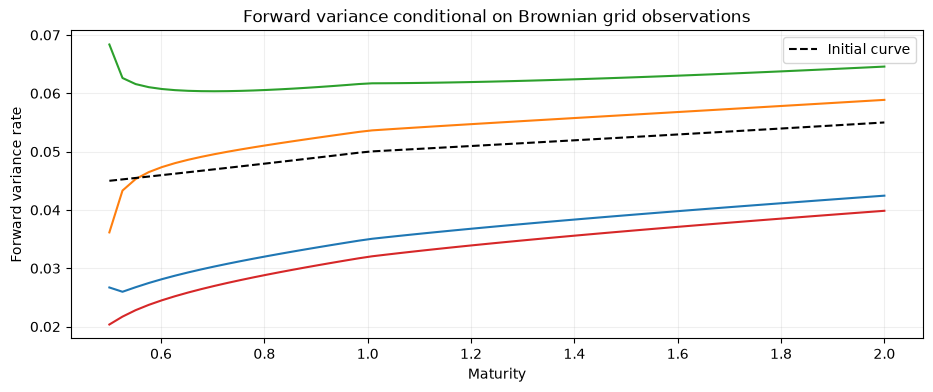

,realized variance at t,conditional mean given increments
0,0.036178,0.026709
1,0.031023,0.036152
2,0.074226,0.068369
3,0.015195,0.020361


In [4]:
index = 32
maturities = np.linspace(.5, 2, 60)
forward = model.variance_model.forward_from_brownian(
    times[:index+1], paths.driver.brownian_increments[:4, :index], maturities)
fig, ax = plt.subplots()
ax.plot(maturities, forward.values.T)
ax.plot(maturities, curve(maturities), 'k--', label='Initial curve')
ax.set(title='Forward variance conditional on Brownian grid observations',
       xlabel='Maturity', ylabel='Forward variance rate')
ax.legend()
plt.show()
pd.DataFrame({'realized variance at t': paths.variance[:4, index],
              'conditional mean given increments': forward.values[:, 0]})

## Finite-factor approximation error

Positive exponential sums yield a finite OU state. Their integrated squared kernel error equals the terminal driver mean-square error under a shared Brownian motion. It is not an asset-price error bound. Refining a fixed rate range eventually reaches a truncation-error floor, which includes unresolved behavior arbitrarily near zero.

,factors,relative L2 error,coupled driver MSE,quadrature error estimate
0,4,0.546440,0.298597,3.518075e-12
1,8,0.235807,0.055605,1.409831e-12
2,16,0.080892,0.006544,2.044372e-14
3,32,0.046135,0.002128,1.625002e-15
4,64,0.040435,0.001635,2.415602e-15


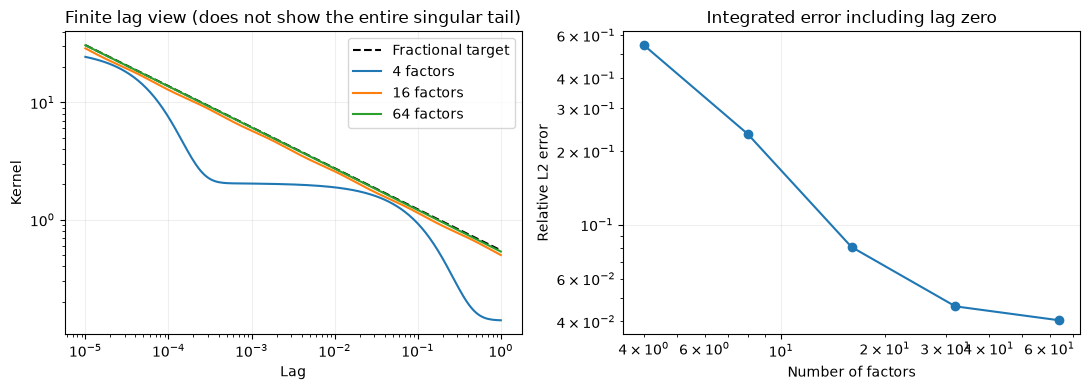

In [5]:
records = []
for n in [4, 8, 16, 32, 64]:
    kernel, error = r.approximate_fractional(h, factors=n, horizon=1.)
    records.append({'factors': n, 'relative L2 error': error.relative_l2_error,
                    'coupled driver MSE': error.squared_error,
                    'quadrature error estimate': error.quadrature_error})
table = pd.DataFrame(records)
display(table)
fig, axes = plt.subplots(1, 2)
lags = np.geomspace(1e-5, 1, 200)
axes[0].loglog(lags, r.FractionalKernel(h)(lags), 'k--', label='Fractional target')
for n in [4, 16, 64]:
    kernel, _ = r.approximate_fractional(h, factors=n)
    axes[0].loglog(lags, kernel(lags), label=f'{n} factors')
axes[0].set(xlabel='Lag', ylabel='Kernel', title='Finite lag view (does not show the entire singular tail)')
axes[0].legend()
axes[1].loglog(table['factors'], table['relative L2 error'], 'o-')
axes[1].set(xlabel='Number of factors', ylabel='Relative L2 error', title='Integrated error including lag zero')
plt.tight_layout()
plt.show()

## Full forward state of the finite-factor model

All OU factors share one Brownian motion. Retaining every factor provides an exact state for this approximating model. The full forward curve at the current maturity equals its realized variance. This differs from conditioning only on Brownian grid increments.

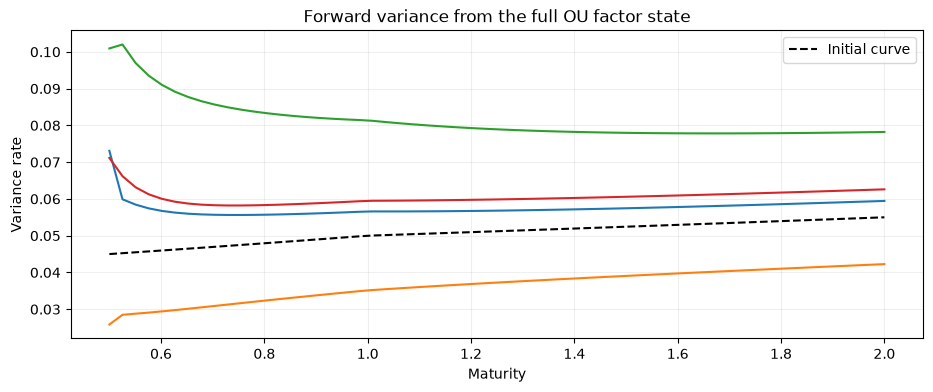

,realized variance,current forward variance
0,0.073085,0.073085
1,0.025846,0.025846
2,0.100925,0.100925
3,0.071146,0.071146


In [6]:
kernel, error = r.approximate_fractional(h, factors=16, tolerance=.15)
lifted_model = r.VolterraBergomi(kernel, eta=.7, rho=-.7, xi0=curve)
lifted = lifted_model.sample(100, times, draws=500, rng=rng, method='factors')
lifted_forward = lifted_model.variance_model.forward_from_factors(
    .5, lifted.driver.factors[:4, index], maturities)
fig, ax = plt.subplots()
ax.plot(maturities, lifted_forward.values.T)
ax.plot(maturities, curve(maturities), 'k--', label='Initial curve')
ax.set(title='Forward variance from the full OU factor state', xlabel='Maturity', ylabel='Variance rate')
ax.legend()
plt.show()
pd.DataFrame({'realized variance': lifted.variance[:4, index],
              'current forward variance': lifted_forward.values[:, 0]})

The examples inspect these specified models on generated data. They do not establish market calibration or predictive quality. The automated tests additionally check analytic covariance, Brownian limits, conditional expectations, common-noise factors, error identities, and invalid inputs.